# (G)VAR extensions: exogenous inputs, nonlinearity and forecasting strategy

Each step builds on the previous model: G-VAR, then exogenous inputs (G-VAR-X), then a leaky nonlinearity, then a fully nonlinear graph network, then a change of forecasting strategy from recursive to direct.

All models use `cave_proofread` (session 4_7) with the same chronological split, normalisation, test windows and metrics: a 15-frame context, then a 5-step forecast. MSE is in standardised log1p units.

Choices are selected on the validation MSE averaged over horizons 1..5. P=15, K=3 throughout: the P x K grid selects it under both one-step and five-step validation.

In [1]:
import copy, shutil, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parents[1]))  # repository root, for models.VAR
from data import load_data
from train import run, evaluate, eval_windows, CONTEXT
import gvar_nonlinear
from exogenous import hold_unknown
from models.VAR import train_varx

EXO = dict(video_pcs=32, behaviour=('treadmill',))  # data loaders
GEXO = dict(video_pcs=32, behaviour='treadmill')     # train.run config
data = load_data('cave_proofread')
data_x = load_data('cave_proofread', **EXO)
print('activity', tuple(data['X'].shape), ' exogenous', tuple(data_x['U'].shape),
      f" (32 video PCs explain {sum(data_x['video_explained']):.0%} of pixel variance, + treadmill)")
print('nonlinear models train on', gvar_nonlinear.device())

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, GRAY = '#52514e', '#a3a29b'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'lines.linewidth': 2, 'figure.dpi': 110,
                     'axes.edgecolor': GRAY, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK})
hs = np.arange(1, 6)
results = {}  # name -> {'test': metrics, 'params': int, 'strategy': str}


def record(name, test, params, strategy='recursive'):
    results[name] = {'test': test, 'params': params, 'strategy': strategy}
    print(f"{name:32s} test MSE h=1 {test['mse'][0]:.4f}  h=5 {test['mse'][4]:.4f}")


# G-VAR family through train.run, P=15 K=3; returns the fitted model and its results
def gvar(name, d=data, strategy='recursive', **cfg):
    model, res = run({'P': 15, 'K': 3, 'strategy': strategy, **cfg}, data=d, verbose=False)
    params = res['parameter_count'] + (res['nonlinear']['parameter_count'] if res['nonlinear'] else 0)
    record(name, res['test']['gvar'], params, strategy)
    return model, res

activity (37840, 1059)  exogenous (37840, 33)  (32 video PCs explain 71% of pixel variance, + treadmill)
nonlinear models train on cuda


## 1. Baselines, VAR and VAR-X

- **Copy-last** repeats the last frame. **Mean** predicts each neuron's training mean.
- **VAR** is a dense population VAR(1) with intercepts (Baturalp's model).
- **VAR-X** adds a per-neuron readout of lagged exogenous inputs $[\mathbf{u}_t, \dots, \mathbf{u}_{t-Q+1}]$, with its own ridge penalty:
  - video: 32 PCA components of the stimulus frame, fitted on training frames. The stimulus is designed in advance, so future frames are known.
  - treadmill speed: lagged one frame and held at its last value during a forecast, since it is not known in advance.

Pupil is left out because it has NaNs in 16% of rows.

In [2]:
def var(name, **kw):
    out = Path('../VAR/runs') / name
    shutil.rmtree(out, ignore_errors=True)
    model, res, _ = train_varx.run('cave_proofread', out, verbose=False, **kw)
    record(name, res['test']['varx'], res['parameter_count'])
    return res

var_res = var('VAR')
var('VAR-X', **EXO)
record('copy-last', var_res['test']['copy_last'], 0)
record('mean', var_res['test']['mean'], 0)

VAR                              test MSE h=1 0.4969  h=5 0.7331
VAR-X                            test MSE h=1 0.4971  h=5 0.7327
copy-last                        test MSE h=1 0.6124  h=5 1.3311
mean                             test MSE h=1 0.7930  h=5 0.7875


## 2. G-VAR, then clamp and intercept

G-VAR shares $(K+1)P = 64$ graph-filter taps across all neurons: $\mathbf{x}_t = \sum_{k,p} h_{kp}\,\mathbf{S}^k\mathbf{x}_{t-p}$, fitted in closed form (ridge).

Two general additions, used in every model from here on:
- **Clamp**: each forecast step is clamped at the neuron's lowest training value before it is fed back. About 79% of all entries sit exactly at that floor (raw activity 0), and activity cannot go lower.
- **Intercept**: an unpenalised constant per neuron.

In [3]:
gvar('G-VAR', clamp=False, intercept=False)
gvar('G-VAR + clamp + intercept');

G-VAR                            test MSE h=1 0.4288  h=5 0.7337
G-VAR + clamp + intercept        test MSE h=1 0.4216  h=5 0.7333


## 3. G-VAR-X

Adds the exogenous inputs of VAR-X. The taps $h$ stay shared, and each neuron gets its own readout $\mathbf{B}$ of the lagged inputs, since $\mathbf{u}$ is a global signal rather than a graph signal. $\mathbf{B}$ is eliminated per neuron in closed form, which leaves a 64-dimensional system for the taps.

In [4]:
gvarx, gvarx_res = gvar('G-VAR-X', data_x, **GEXO)
print(f"selected Q={gvarx_res['Q']}, lam_exo={gvarx_res['lam_exo']:g}")

G-VAR-X                          test MSE h=1 0.4216  h=5 0.7330
selected Q=1, lam_exo=1


The inputs barely help: on their own, the 32 pixel PCs and treadmill speed explain about 1% of the validation variance.

## 4. Leaky G-VAR-X

The first nonlinearity: extra taps on $\mathbf{S}^k\,\mathrm{relu}(\mathbf{x}_{t-p})$. Together with $h_{kp}$, this is a LeakyReLU of the inputs with a learned slope per tap. The nonlinearity acts before the graph filter, so the model is still linear in its parameters and still fitted in closed form. It is nonlinear in the inputs, but only additively, with one kink.

In [5]:
leakyx, _ = gvar('Leaky G-VAR-X', data_x, leaky=True, **GEXO)
pd.DataFrame({n: results[n]['test']['mse'] for n in ('G-VAR-X', 'Leaky G-VAR-X')}, index=hs).T.round(4)

Leaky G-VAR-X                    test MSE h=1 0.4092  h=5 0.9757


,1,2,3,4,5
G-VAR-X,0.4216,0.7134,0.7276,0.7310,0.7330
Leaky G-VAR-X,0.4092,0.7365,0.8525,0.9487,0.9757


Better at h=1, much worse from h=3 on. The reason: for a silent neuron, the one-step forecast is slightly above the floor, an average of "stays silent" and "starts firing". Fed back as an input, that value looks like the onset of activity, and the leaky model's steep silent-regime slope amplifies it.

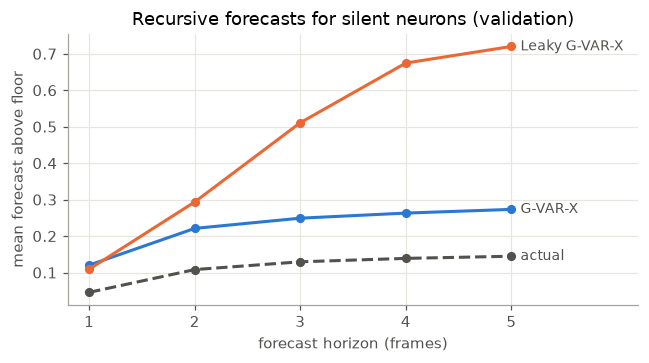

In [6]:
# Neurons silent through the whole 15-frame context: how far above the floor are the forecasts?
xw, uw = eval_windows(data_x, 'val', 5)
past, target = xw[:, :CONTEXT], xw[:, CONTEXT:]
u = hold_unknown(uw, data_x['known_ahead'], CONTEXT)[:, CONTEXT - gvarx.Q + 1:]  # as in evaluate()
floor = data_x['floor']
silent = (past <= floor + 1e-4).all(1)  # [windows, neurons]
above = lambda p: [(p[:, j] - floor)[silent].mean().item() for j in range(5)]
idx = torch.arange(len(past)).split(2048)
drift = {'actual': above(target)}
for name, m in (('G-VAR-X', gvarx), ('Leaky G-VAR-X', leakyx)):
    drift[name] = above(torch.cat([m.rollout(past[i], 5, u[i]) for i in idx]))

fig, ax = plt.subplots(figsize=(6, 3.4))
for (name, v), color, style in zip(drift.items(), (INK, BLUE, ORANGE), ('--', '-', '-')):
    ax.plot(hs, v, style, color=color, marker='o', markersize=5)
    ax.annotate(name, (5, v[-1]), xytext=(6, 0), textcoords='offset points', va='center', color=INK, fontsize=9)
ax.set(xlabel='forecast horizon (frames)', ylabel='mean forecast above floor',
       title='Recursive forecasts for silent neurons (validation)', xticks=hs, xlim=(0.8, 6.2))
plt.tight_layout()
plt.show()

## 5. Nonlinear G-VAR-X

Stacked graph filters with ReLUs between them, on top of the frozen G-VAR-X from step 3:

$$\mathbf{H}^{l} = \mathrm{relu}\Big(\sum_k \mathbf{S}^k \mathbf{H}^{l-1} \mathbf{W}^l_k + \mathbf{b}^l\Big), \qquad \hat{\mathbf{x}}_t = \text{G-VAR-X}(\cdot) + \sum_k \mathbf{S}^k \mathbf{H}^L \mathbf{w}_k$$

- $\mathbf{H}^0$ holds each node's 15 lags and a learned projection of the exogenous lags.
- 2 layers of 32 channels with K=3, trained with Adam on the one-step loss.
- The readout starts at zero, so epoch 0 is G-VAR-X.

Stopped on the five-step validation score, it keeps epoch 0, i.e. it reduces to G-VAR-X. It is stopped on **one-step** validation here instead, to show what the nonlinearity buys and costs.

Nonlinear G-VAR-X                test MSE h=1 0.3455  h=5 0.8257


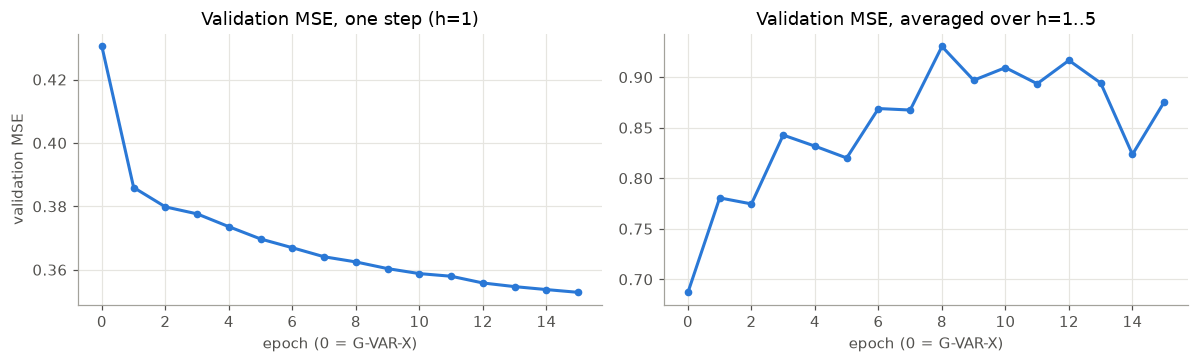

In [7]:
def nonlinear_one_step(name, linear, d, epochs=15):
    val = eval_windows(d, 'val', 5)
    def score(m):
        mse = evaluate(m, val, 5, d['known_ahead'])['gvar']['mse']
        return {'val_mse': mse[0], 'val_mse_h1': mse[0], 'val_avg': sum(mse) / 5}  # stop on h=1
    model = gvar_nonlinear.NonlinearGVAR(copy.deepcopy(linear)).to(gvar_nonlinear.device())
    model, history, best = gvar_nonlinear.train(model, d, score, epochs=epochs, verbose=False)
    test = evaluate(model, eval_windows(d, 'test', 5), 5, d['known_ahead'])['gvar']
    record(name, test, linear.parameter_count + model.parameter_count)
    return pd.DataFrame(history)

hist = nonlinear_one_step('Nonlinear G-VAR-X', gvarx, data_x)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, title in zip(axes, ('val_mse_h1', 'val_avg'), ('one step (h=1)', 'averaged over h=1..5')):
    ax.plot(hist['epoch'], hist[col], color=BLUE, marker='o', markersize=4)
    ax.set(xlabel='epoch (0 = G-VAR-X)', title=f'Validation MSE, {title}')
axes[0].set_ylabel('validation MSE')
plt.tight_layout()
plt.show()

One-step error keeps falling while the five-step error rises from the first epoch on: the same drift as the leaky model, but stronger.

## 6. Forecasting strategy: recursive vs direct

So far every model forecasts **recursively**: one model predicts the next frame and is fed its own predictions. The nonlinear models fail because those fed-back predictions do not look like real activity.

A **direct** model (as in STGCN or Graph WaveNet) has one head per horizon, and each head forecasts from the observed context only:

$$\hat{\mathbf{x}}_{t+j} = f_j(\mathbf{x}_{t-1}, \dots, \mathbf{x}_{t-P}, \mathbf{u}), \qquad j = 0, \dots, 4$$

- Nothing is fed back, so errors cannot compound, and each head minimises the error at its own horizon.
- Linear and leaky heads are still fitted in closed form, one ridge problem per horizon. Behaviour is held at the forecast origin in training as in evaluation, so no head uses inputs it could not know.
- The nonlinear network gets one output per horizon on top of the direct G-VAR-X, trained on the error of all five horizons and stopped on the five-step validation score.
- Cost: 5x the parameters. The heads also no longer describe one-step dynamics.

The evaluation is unchanged: same windows, targets and information. But the protocol asks for recursive forecasts, so direct is reported as a separate strategy.

In [8]:
gvar('G-VAR-X (direct)', data_x, 'direct', **GEXO)
gvar('Leaky G-VAR-X (direct)', data_x, 'direct', leaky=True, **GEXO)
gvar('Nonlinear G-VAR-X (direct)', data_x, 'direct', nl_layers=2, **GEXO);

G-VAR-X (direct)                 test MSE h=1 0.4216  h=5 0.7296
Leaky G-VAR-X (direct)           test MSE h=1 0.4092  h=5 0.7295
Nonlinear G-VAR-X (direct)       test MSE h=1 0.3680  h=5 0.7252


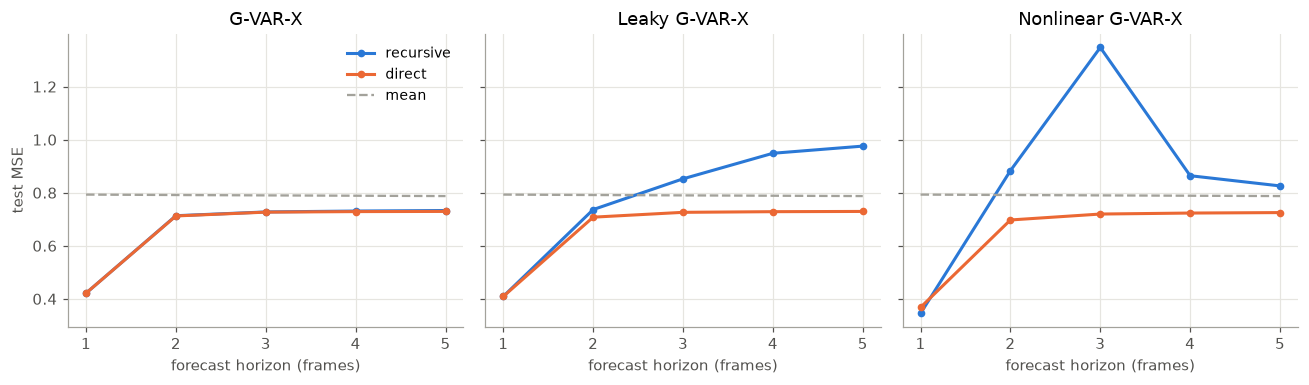

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, base in zip(axes, ('G-VAR-X', 'Leaky G-VAR-X', 'Nonlinear G-VAR-X')):
    for name, color, label in ((base, BLUE, 'recursive'), (f'{base} (direct)', ORANGE, 'direct')):
        ax.plot(hs, results[name]['test']['mse'], color=color, marker='o', markersize=4, label=label)
    ax.plot(hs, results['mean']['test']['mse'], '--', color=GRAY, linewidth=1.5, label='mean')
    ax.set(title=base, xlabel='forecast horizon (frames)', xticks=hs)
axes[0].set_ylabel('test MSE')
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

With the direct strategy the nonlinear models stop drifting. Direct nonlinear G-VAR-X is the best model from h=2 on and on average. At h=1 the recursive nonlinear model is slightly better (0.346 vs 0.368), but it fails from h=2 onwards.

## 7. All models

In [10]:
order = ['mean', 'copy-last', 'VAR', 'VAR-X', 'G-VAR', 'G-VAR + clamp + intercept', 'G-VAR-X', 'Leaky G-VAR-X',
         'Nonlinear G-VAR-X', 'G-VAR-X (direct)', 'Leaky G-VAR-X (direct)', 'Nonlinear G-VAR-X (direct)']
table = pd.DataFrame({n: {'strategy': results[n]['strategy'], 'parameters': results[n]['params'],
                          **{f'MSE h={h}': results[n]['test']['mse'][h - 1] for h in hs},
                          'MSE avg': np.mean(results[n]['test']['mse']),
                          'Pearson h=1': results[n]['test']['pearson'][0],
                          'Pearson h=5': results[n]['test']['pearson'][4]} for n in order}).T
table['parameters'] = table['parameters'].astype(int)
num = [c for c in table.columns if c not in ('strategy', 'parameters')]
table[num] = table[num].astype(float)
table.style.format({c: '{:.4f}' for c in num} | {'parameters': '{:,}'}) \
    .highlight_min(subset=[c for c in num if c.startswith('MSE')], color='#d7e6f8')

,strategy,parameters,MSE h=1,MSE h=2,MSE h=3,MSE h=4,MSE h=5,MSE avg,Pearson h=1,Pearson h=5
mean,recursive,0,0.7930,0.7914,0.7900,0.7888,0.7875,0.7901,0.0000,0.0000
copy-last,recursive,0,0.6124,1.2169,1.3140,1.3303,1.3311,1.1610,0.5984,0.1093
VAR,recursive,"1,122,540",0.4969,0.7087,0.7211,0.7275,0.7331,0.6775,0.5792,0.1892
VAR-X,recursive,"1,157,487",0.4971,0.7084,0.7207,0.7271,0.7327,0.6772,0.5788,0.1914
G-VAR,recursive,60,0.4288,0.7131,0.7285,0.7318,0.7337,0.6672,0.6634,0.1840
G-VAR + clamp + intercept,recursive,"1,119",0.4216,0.7138,0.7280,0.7314,0.7333,0.6656,0.6705,0.1842
G-VAR-X,recursive,"36,066",0.4216,0.7134,0.7276,0.7310,0.7330,0.6653,0.6704,0.1866
Leaky G-VAR-X,recursive,"36,126",0.4092,0.7365,0.8525,0.9487,0.9757,0.7845,0.6839,0.1801
Nonlinear G-VAR-X,recursive,"43,571",0.3455,0.8832,1.3475,0.8642,0.8257,0.8532,0.7413,0.0988
G-VAR-X (direct),direct,"180,330",0.4216,0.7125,0.7269,0.7289,0.7296,0.6639,0.6704,0.1897


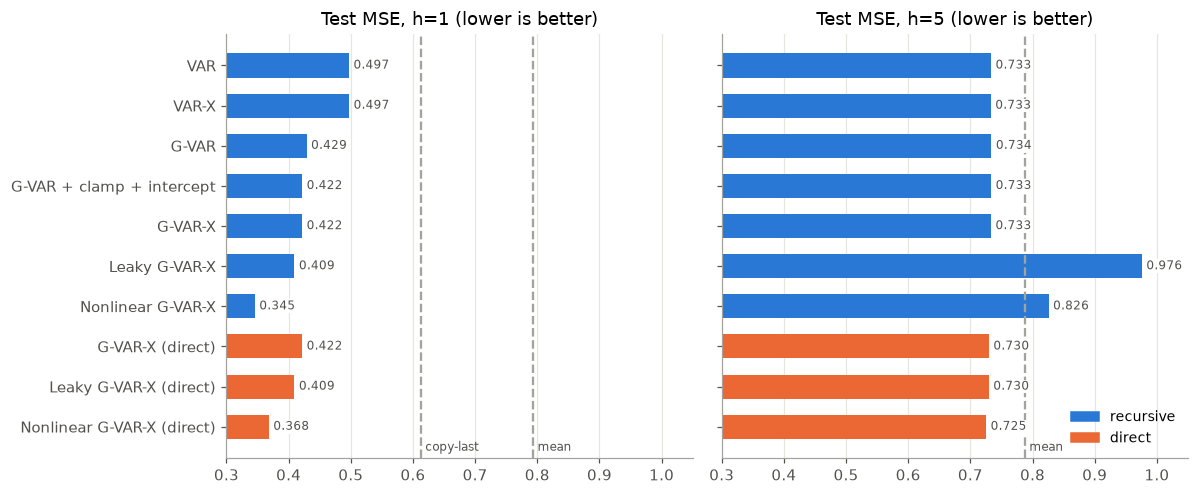

In [11]:
models = [n for n in order if n not in ('mean', 'copy-last')]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
axes[0].invert_yaxis()  # once: the y axis is shared
for ax, h in zip(axes, (1, 5)):
    v = [results[n]['test']['mse'][h - 1] for n in models]
    y = np.arange(len(models))
    ax.barh(y, v, height=0.6, color=[ORANGE if results[n]['strategy'] == 'direct' else BLUE for n in models])
    for b in ('copy-last', 'mean'):
        ref = results[b]['test']['mse'][h - 1]
        if ref < 1.0:
            ax.axvline(ref, color=GRAY, linestyle='--', linewidth=1.5)
            ax.annotate(b, (ref, len(models) - 0.4), xytext=(3, 0), textcoords='offset points', color=INK, fontsize=8)
    for yi, vi in zip(y, v):
        ax.annotate(f'{vi:.3f}', (vi, yi), xytext=(3, 0), textcoords='offset points', va='center', color=INK, fontsize=8,
                    bbox=dict(facecolor='white', edgecolor='none', pad=0.5))
    ax.set(title=f'Test MSE, h={h} (lower is better)', yticks=y, yticklabels=models, xlim=(0.3, 1.05))
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(True)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE)], labels=['recursive', 'direct'],
               frameon=False, fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

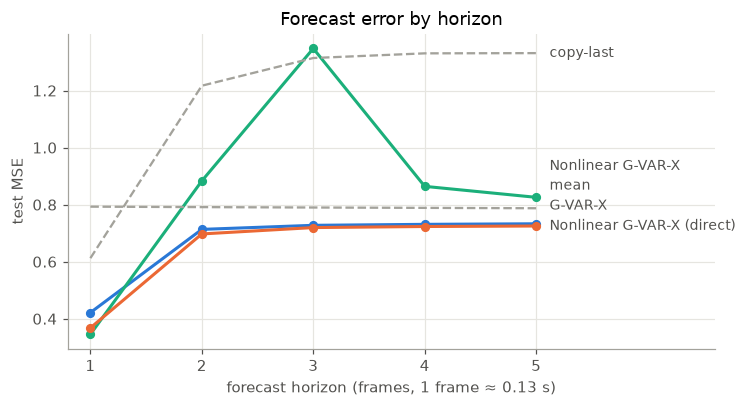

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
lines = [('G-VAR-X', BLUE, '-'), ('Nonlinear G-VAR-X', AQUA, '-'), ('Nonlinear G-VAR-X (direct)', ORANGE, '-'),
         ('copy-last', GRAY, '--'), ('mean', GRAY, '--')]
for name, color, style in lines:
    ax.plot(hs, results[name]['test']['mse'], style, color=color, marker='o' if style == '-' else None, markersize=5,
            linewidth=2 if style == '-' else 1.5)
# end labels, spread apart so close lines do not collide
ends = sorted((results[n]['test']['mse'][-1], n) for n, _, _ in lines)
y_prev = -np.inf
for y, name in ends:
    y_prev = max(y, y_prev + 0.07)
    ax.annotate(name, (5, y), xytext=(5.12, y_prev), textcoords='data', va='center', color=INK, fontsize=9)
ax.set(xlabel='forecast horizon (frames, 1 frame ≈ 0.13 s)', ylabel='test MSE', xticks=hs, xlim=(0.8, 6.6),
       title='Forecast error by horizon')
plt.tight_layout()
plt.show()

## Takeaways

Test MSE on `cave_proofread`, single run per model.

- **The connectome graph helps at one step.** G-VAR beats the dense VAR at h=1 (0.429 vs 0.497, -14%) with 60 parameters instead of 1.1M. From h=2 on, the dense VAR is marginally better (0.709 vs 0.713), and all linear models are within about 0.01.
- **Clamp and intercept give a small, free gain at h=1** (0.429 to 0.422), and change little at longer horizons.
- **Exogenous inputs barely matter.** G-VAR-X and VAR-X are within 0.001 of their counterparts without inputs, consistent with pixel PCs and treadmill explaining about 1% of the variance on their own.
- **Recursively, nonlinearity trades long-horizon accuracy for one-step accuracy.**
  - Leaky G-VAR-X improves h=1 by 3% (0.409), but at h=5 it is worse than predicting the mean (0.976 vs 0.788).
  - Nonlinear G-VAR-X improves h=1 by 18% (0.346), but at h=3 it is worse than copy-last (1.35 vs 1.31).
  - Cause: silent neurons dominate the data, and their averaged one-step forecasts look like activity onsets once they are fed back.
- **The drift comes from the forecasting strategy, not from the nonlinearity.** Forecasting directly:
  - Leaky G-VAR-X drops from 0.976 to 0.730 at h=5, on par with linear.
  - Nonlinear G-VAR-X is the best model from h=2 on. It has the lowest average MSE (0.647 vs 0.665 for recursive G-VAR-X, -3%) and the best correlations among the models that do not drift (Pearson 0.72 at h=1, 0.20 at h=5).
  - Its gain is concentrated in the first two frames (about 0.27 s). At h=5 it is 1% better than linear (0.725 vs 0.733).
- **Caveats.**
  - These are single runs. Seed-to-seed variation of the trained models is of the order of 0.01 at h=1 (direct nonlinear gave 0.356 in an earlier run), so small differences, especially between the linear models, are not conclusive.
  - Direct forecasting breaks the protocol's recursive rule. It is reported as a separate strategy, with the same windows, targets and inputs as every other model.